# 00 - Exploratory data analysis of the wine dataset
Wine Quality dataset (red and white wines), after removing the duplicated rows

The full EDA is in the ML report. Here we only repeat the parts that matter for the networks:
how the quality is distributed, which variables are related to it, how different red and white wines
are (important for notebook 07), and the scale of the variables (why we standardise them).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils import *

set_style()
wine = load_wine()
print(wine.shape, "| red:", wine.is_red.sum(), "white:", (1 - wine.is_red).sum())
wine[PHYSCHEM].describe().T[["mean", "std", "min", "max"]].round(3)

(5320, 16) | red: 1359 white: 3961


,mean,std,min,max
fixed acidity,7.215,1.320,3.800,15.900
volatile acidity,0.344,0.168,0.080,1.580
citric acid,0.318,0.147,0.000,1.660
residual sugar,5.048,4.500,0.600,65.800
chlorides,0.057,0.037,0.009,0.611
free sulfur dioxide,30.037,17.805,1.000,289.000
total sulfur dioxide,114.109,56.774,6.000,440.000
density,0.995,0.003,0.987,1.039
pH,3.225,0.160,2.720,4.010
sulphates,0.533,0.150,0.220,2.000


The variables have very different scales: total sulfur dioxide goes up to about 440 while density
is always around 0.99 with a standard deviation of 0.003. This is why every input is standardised
before training the networks.

In [2]:
corr = pd.DataFrame({
    "All wines": wine[PHYSCHEM + ["quality"]].corr()["quality"][PHYSCHEM],
    "Red": wine[wine.is_red == 1][PHYSCHEM + ["quality"]].corr()["quality"][PHYSCHEM],
    "White": wine[wine.is_red == 0][PHYSCHEM + ["quality"]].corr()["quality"][PHYSCHEM],
}).sort_values("All wines")
corr.round(3)

,All wines,Red,White
density,-0.326,-0.184,-0.338
volatile acidity,-0.265,-0.395,-0.191
chlorides,-0.202,-0.131,-0.218
fixed acidity,-0.080,0.119,-0.125
residual sugar,-0.057,0.014,-0.117
total sulfur dioxide,-0.050,-0.178,-0.183
pH,0.040,-0.055,0.124
sulphates,0.042,0.249,0.053
free sulfur dioxide,0.054,-0.050,0.011
citric acid,0.098,0.228,0.007


Figure saved -> ../results/figures/wine_eda.png


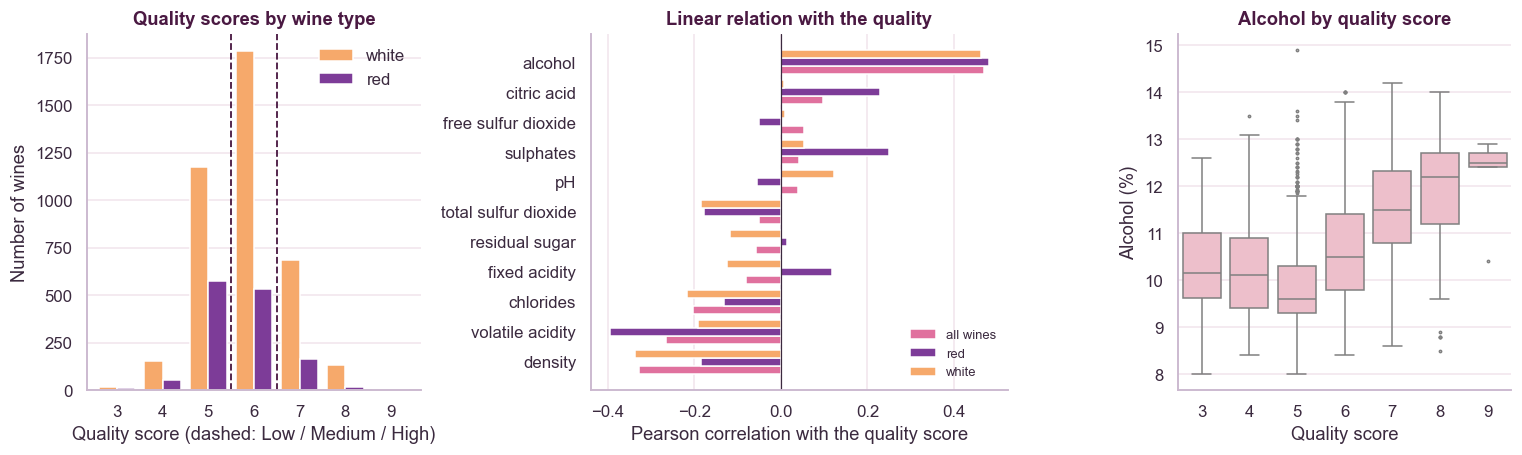

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), gridspec_kw=dict(width_ratios=[1.0, 1.25, 1.0]))
ax = axes[0]
counts = wine.groupby(["quality", "wine_type"]).size().unstack(fill_value=0)
counts[["white", "red"]].plot.bar(ax=ax, color=[APRICOT, PURPLE], width=0.8, rot=0)
for q, c in zip([5.5, 6.5], [PLUM, PLUM]):
    ax.axvline(list(counts.index).index(int(q - 0.5)) + 0.5, color=c, ls="--", lw=1.2)
ax.set_xlabel("Quality score (dashed: Low / Medium / High)")
ax.set_ylabel("Number of wines")
ax.set_title("Quality scores by wine type")
ax.legend(title=None)
ax.grid(axis="x", visible=False)

ax = axes[1]
yy = np.arange(len(corr))
ax.barh(yy - 0.27, corr["All wines"], 0.27, color=PINK, label="all wines")
ax.barh(yy, corr["Red"], 0.27, color=PURPLE, label="red")
ax.barh(yy + 0.27, corr["White"], 0.27, color=APRICOT, label="white")
ax.set_yticks(yy, corr.index)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Pearson correlation with the quality score")
ax.set_title("Linear relation with the quality")
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)

ax = axes[2]
sns.boxplot(data=wine, x="quality", y="alcohol", ax=ax, color=ROSE, fliersize=1.5, linewidth=1)
ax.set_xlabel("Quality score")
ax.set_ylabel("Alcohol (%)")
ax.set_title("Alcohol by quality score")
fig.tight_layout()
save(fig, "wine_eda.png")
plt.show()

## Summary

* The quality is concentrated in the scores 5 and 6, and scores 3, 4, 8 and 9 are rare, so the
  regression target is very unbalanced and the High class (7 or more) is the smallest one.
* No variable is strongly related to the quality. Alcohol has the largest correlation (0.47) for both
  types. The most negative ones are density (-0.33), which decreases when the alcohol increases, and
  volatile acidity (-0.27), which is the most negative one for red wines (-0.40).
* Some relations change with the type of wine: sulphates (0.25 vs 0.05) and citric acid (0.23 vs 0.01)
  are related to the quality of red wines but not of white wines. Total sulfur dioxide has almost no
  correlation with all the wines together (-0.05) but -0.18 inside each type, because red wines have
  much less of it: mixing the two types hides the relation. This is one reason why the networks use
  `is_red` (notebook 05) and why the red wines need their own scaling (notebook 07).
* The variables have very different scales, so they must be standardised.